# 04 · Checking the L = 9 minima

This notebook runs further checks on Min 1 (Newton) and Min 2 (DE) from notebook 03. The optima are read from `results/minima.json`.

1. Coupling-space Hessians at fixed $J$, computed in the canonical frame and displayed in the standard frame.
2. Curvature of Min 2 along $J$, which DE held fixed.
3. Full $6 \times 6$ Hessians at both minima.
4. Reduced $5 \times 5$ Hessians in the standard frame, with $c_{YZ+ZY}$ pinned at 0. These are the headline curvature numbers.
5. Level-spacing ratio $\langle r \rangle$: do the complex couplings push the statistics from GOE towards GUE?
6. Check that flipping the sign of the imaginary couplings gives the complex-conjugate Hamiltonian.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from spin_eth import COUPLINGS, J_PRX, PARAMS, CanonicalModel, to_standard_frame, two_site_coupling, z_rotation_matrix
from spin_eth.analysis import describe_modes, fd_hessian, n_negative
from spin_eth.constants import R_GOE, R_GUE, R_POISSON
from spin_eth.io import load_json, save_json
from spin_eth.operators import SZ, site_operator
from spin_eth.search import reduced_standard_hessian

RESULTS = Path("../results")
L, l = 9, 3
model = CanonicalModel(L, l)
stored = load_json(RESULTS / "minima.json")["L9"]
x_min1 = np.array(stored["min1_canonical"])
x_min1_unrounded = np.array(stored["min1_canonical_unrounded"])
x_min2 = np.array(stored["min2_canonical"])
x_min2_4dp = np.concatenate([[J_PRX], stored["min2_couplings_4dp"]])

phi_prx = model.phi_mfim()
print(f"L={L}, l={l}:  Phi(PRX) = {phi_prx:.6e}")

L=9, l=3:  Phi(PRX) = 9.813847e-02


## 1. Coupling-space Hessians at fixed J

At each minimum the $5 \times 5$ Hessian over $[c_{XX}, c_{YY}, c_{XY+YX}, c_{XZ+ZX}, c_{YZ+ZY}]$ is computed with $J$ held fixed, in the canonical frame where the search ran (finite-difference step 0.05). For display, the couplings are rotated about Z into the standard frame, and the eigenvectors are shown as $R\,v$, where $R$ is the coefficient map of that rotation.

The rotation leaves $J$, the Z field and the edge fields unchanged, so it does not alter the Hamiltonian family. However, $R$ is not orthogonal in these coordinates (it would be if $c_{XY+YX}$ were scaled by $1/\sqrt2$). So $R\,v$ shows how each mode is oriented but is not exactly an eigenvector of the standard-frame Hessian. The eigenvalues listed are those of the canonical-frame Hessian. A mode is tagged "← gauge" when it overlaps the residual Z-rotation direction by more than 0.7.

For Min 1 this Hessian uses the unrounded optimum from notebook 03, as the original analysis did; every other Min 1 check in this notebook uses the 6-decimal values. At the rounded point two eigenvalues shift by 1 in the fourth decimal.

In [2]:
def coupling_hessian_report(label, J, c5):
    x_std, rot = to_standard_frame(np.concatenate([[J], c5]))
    H, phi = fd_hessian(model.phi_fixed_J(J), c5, eps=0.05)
    evals, evecs = np.linalg.eigh(H)
    evecs_std = z_rotation_matrix(rot) @ evecs

    cXX, cYY, cXY, cXZ, _ = x_std[1:]
    gauge = np.array([-cXY, cXY, 2 * (cXX - cYY), 0.0, -cXZ])
    gauge /= np.linalg.norm(gauge)

    print(f"{label}  (J = {J:.4f}):  Phi = {phi:.6e}  ({phi_prx / phi:.4f}x vs PRX)")
    print(f"  {'coupling':>8}  {'canonical':>9}  {'standard':>9}   (Z rotation {np.degrees(rot):.1f} deg)")
    for name, a, b in zip(COUPLINGS, c5, x_std[1:]):
        print(f"  {name:>8}  {a:+9.4f}  {b:+9.4f}")
    for k, ev in enumerate(evals):
        v = evecs_std[:, k]
        dom = ", ".join(f"{COUPLINGS[i]}({v[i]:+.2f})" for i in np.argsort(np.abs(v))[::-1][:3])
        tag = "  <- gauge" if abs(v @ gauge) > 0.7 else ""
        print(f"    mode {k + 1}: {ev:+.4e}   [{dom}]{tag}")
    print(f"  {np.sum(evals < -1e-3)} negative, {np.sum(np.abs(evals) < 0.05)} near zero (<0.05), {np.sum(evals > 1e-3)} positive\n")
    return evals


evals_c_min1 = coupling_hessian_report("Min 1 (Newton)", x_min1_unrounded[0], x_min1_unrounded[1:])
evals_c_min2 = coupling_hessian_report("Min 2 (DE)", J_PRX, x_min2[1:])

Min 1 (Newton)  (J = 0.0823):  Phi = 7.154433e-02  (1.3717x vs PRX)
  coupling  canonical   standard   (Z rotation 0.2 deg)
        XX    +0.5394    +0.5364
        YY    +0.7597    +0.7627
     XY+YX    -0.4434    -0.4427
     XZ+ZX    +0.3585    +0.3585
     YZ+ZY    +0.0012    +0.0000
    mode 1: +8.1752e-01   [YY(-0.77), XX(+0.40), YZ+ZY(-0.36)]  <- gauge
    mode 2: +9.4436e-01   [YZ+ZY(+0.82), YY(-0.41), XZ+ZX(-0.33)]
    mode 3: +1.2360e+00   [XZ+ZX(+0.83), YZ+ZY(+0.42), YY(+0.27)]
    mode 4: +1.6700e+00   [XY+YX(-0.69), XX(+0.56), YY(+0.34)]
    mode 5: +1.9780e+00   [XY+YX(-0.70), XX(-0.67), YY(-0.22)]
  0 negative, 0 near zero (<0.05), 5 positive



Min 2 (DE)  (J = 0.0639):  Phi = 7.031195e-02  (1.3958x vs PRX)
  coupling  canonical   standard   (Z rotation -69.3 deg)
        XX    +1.3102    +0.3066
        YY    +0.1564    +1.1601
     XY+YX    -0.0096    +0.3884
     XZ+ZX    +0.2660    +0.7534
     YZ+ZY    -0.7049    -0.0000
    mode 1: +5.7585e-01   [XY+YX(-0.72), XX(-0.48), YZ+ZY(+0.37)]
    mode 2: +6.3830e-01   [YY(+1.03), XX(-0.31), YZ+ZY(+0.27)]
    mode 3: +1.0040e+00   [XX(-0.79), XZ+ZX(-0.50), XY+YX(+0.25)]
    mode 4: +1.4419e+00   [YZ+ZY(-0.63), XZ+ZX(+0.62), XX(-0.51)]
    mode 5: +1.7692e+00   [YZ+ZY(-0.63), XZ+ZX(-0.57), XY+YX(-0.37)]
  0 negative, 0 near zero (<0.05), 5 positive



## 2. Min 2 along J

DE held $J = J_\mathrm{PRX}$ fixed, so §1 does not test the curvature of Min 2 along $J$. A broad scan in $J$ looks for a distant lower basin, and a second difference with the same step (0.05) gives the local curvature. The couplings are the DE optimum rounded to 4 decimals.

J scan:   0%|          | 0/81 [00:00<?, ?it/s]

Min 2 at J = J_PRX = 0.063907:  Phi = 7.031196e-02  (1.3958x vs PRX)
Scan over J in [-2.0, 6.0] (81 points): lowest Phi = 7.127148e-02 at J = +0.000
  confirmed: no scanned J is lower than J_PRX
Curvature d2Phi/dJ2 at J_PRX = +9.5976e-01;  coupling-space eigenvalues (section 1): +5.759e-01, +6.383e-01, +1.004e+00, +1.442e+00, +1.769e+00


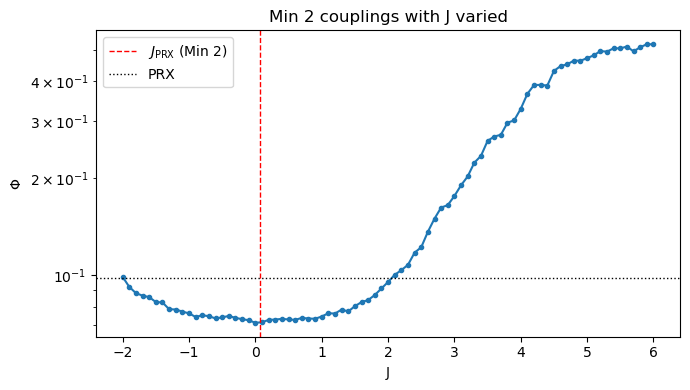

In [3]:
def phi_of_J(J):
    return model.phi(np.concatenate([[J], x_min2_4dp[1:]]))


phi_center = phi_of_J(J_PRX)
J_scan = np.linspace(-2.0, 6.0, 81)
phi_J = np.array([phi_of_J(J) for J in tqdm(J_scan, desc="J scan", leave=False)])
i_best = np.argmin(phi_J)

eps = 0.05
curv_J = (phi_of_J(J_PRX + eps) - 2 * phi_center + phi_of_J(J_PRX - eps)) / eps**2

print(f"Min 2 at J = J_PRX = {J_PRX:.6f}:  Phi = {phi_center:.6e}  ({phi_prx / phi_center:.4f}x vs PRX)")
print(f"Scan over J in [{J_scan[0]:.1f}, {J_scan[-1]:.1f}] ({len(J_scan)} points): lowest Phi = {phi_J[i_best]:.6e} at J = {J_scan[i_best]:+.3f}")
print("  *** lower point found: Min 2 is not a minimum in J ***" if phi_J[i_best] < phi_center * (1 - 5e-4)
      else "  confirmed: no scanned J is lower than J_PRX")
print(f"Curvature d2Phi/dJ2 at J_PRX = {curv_J:+.4e};  coupling-space eigenvalues (section 1): "
      + ", ".join(f"{e:+.3e}" for e in evals_c_min2))

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(J_scan, phi_J, "o-", ms=3)
ax.axvline(J_PRX, color="r", ls="--", lw=1, label=r"$J_\mathrm{PRX}$ (Min 2)")
ax.axhline(phi_prx, color="k", ls=":", lw=1, label="PRX")
ax.set_xlabel("J")
ax.set_ylabel(r"$\Phi$")
ax.set_title("Min 2 couplings with J varied")
ax.legend()
fig.tight_layout()
plt.show()

## 3. Full 6 × 6 Hessians

The curvature check in §2 is diagonal only. The full Hessian over all six parameters adds the $J$–coupling cross terms. It uses the same recipe for both minima (step 0.06, as in the Newton search).

In [4]:
hess6 = {}
for label, x in (("Min 2 (DE, 4 d.p.)", x_min2_4dp), ("Min 1 (Newton)", x_min1)):
    H6, phi = fd_hessian(model.phi, x, eps=0.06, progress=True, desc=label)
    evals, evecs = np.linalg.eigh(H6)
    hess6[label] = evals
    print(f"{label}: " + ", ".join(f"{n}={v:+.6f}" for n, v in zip(PARAMS, x)))
    print(f"  Phi = {phi:.6e}  ({phi_prx / phi:.4f}x vs PRX)")
    print(describe_modes(evals, evecs, PARAMS))
    print(f"  {n_negative(evals)} negative eigenvalues\n")

print(pd.DataFrame(hess6, index=pd.RangeIndex(1, 7, name="mode")).to_string(float_format="{:+.4e}".format))

Min 2 (DE, 4 d.p.):   0%|          | 0/21 [00:00<?, ?it/s]

Min 2 (DE, 4 d.p.): J=+0.063907, XX=+1.310200, YY=+0.156400, XY+YX=-0.009600, XZ+ZX=+0.266000, YZ+ZY=-0.704900
  Phi = 7.031196e-02  (1.3958x vs PRX)
    mode 1: +4.8400e-01  [pos]  XY+YX(+0.72), XX(-0.50)
    mode 2: +5.4587e-01  [pos]  XX(+0.76), XY+YX(+0.53)
    mode 3: +7.3344e-01  [pos]  J(+0.83), XX(-0.38)
    mode 4: +9.0657e-01  [pos]  YY(-0.80), YZ+ZY(+0.42)
    mode 5: +1.1984e+00  [pos]  YZ+ZY(+0.87), YY(+0.37)
    mode 6: +1.5197e+00  [pos]  XZ+ZX(+0.84), XY+YX(-0.38)
  0 negative eigenvalues



Min 1 (Newton):   0%|          | 0/21 [00:00<?, ?it/s]

Min 1 (Newton): J=+0.082343, XX=+0.539440, YY=+0.759689, XY+YX=-0.443422, XZ+ZX=+0.358522, YZ+ZY=+0.001237
  Phi = 7.154433e-02  (1.3717x vs PRX)
    mode 1: +3.8882e-01  [pos]  YZ+ZY(-0.70), XZ+ZX(+0.60)
    mode 2: +6.5324e-01  [pos]  YY(-0.65), YZ+ZY(+0.51)
    mode 3: +8.8519e-01  [pos]  J(-0.74), XY+YX(-0.47)
    mode 4: +1.0930e+00  [pos]  XZ+ZX(-0.72), YY(-0.51)
    mode 5: +1.2596e+00  [pos]  XY+YX(-0.85), J(+0.40)
    mode 6: +1.4883e+00  [pos]  XX(+0.84), YY(+0.38)
  0 negative eigenvalues

      Min 2 (DE, 4 d.p.)  Min 1 (Newton)
mode                                    
1            +4.8400e-01     +3.8882e-01
2            +5.4587e-01     +6.5324e-01
3            +7.3344e-01     +8.8519e-01
4            +9.0657e-01     +1.0930e+00
5            +1.1984e+00     +1.2596e+00
6            +1.5197e+00     +1.4883e+00


## 4. Reduced Hessians in the standard frame

Pinning $c_{YZ+ZY} = 0$ fixes the residual Z rotation. What remains is the Hessian over $[J, c_{XX}, c_{YY}, c_{XY+YX}, c_{XZ+ZX}]$ (step 0.05). It differs from §3, where $c_{YZ+ZY}$ is free, and from §1, where $J$ is fixed and $c_{YZ+ZY}$ is free.

In [5]:
reduced = {}
for label, x in (("Min 1 (Newton)", x_min1), ("Min 2 (DE)", x_min2)):
    res = reduced_standard_hessian(model, x, progress=True, desc=label)
    reduced[label] = res
    print(f"{label}: standard frame (rotation {np.degrees(res['rotation']):.4f} deg): "
          + ", ".join(f"{n}={v:.6g}" for n, v in zip(PARAMS[:5], res["x_std"][:5]))
          + f", YZ+ZY={res['x_std'][5]:.1e}")
    print(f"  Phi = {res['phi']:.8e}  ({phi_prx / res['phi']:.6f}x vs PRX)")
    print(describe_modes(res["evals"], res["evecs"], PARAMS[:5]))
    print(f"  {n_negative(res['evals'])} negative eigenvalues\n")

print(pd.DataFrame({k: r["evals"] for k, r in reduced.items()}, index=pd.RangeIndex(1, 6, name="mode"))
      .to_string(float_format="{:+.4e}".format))

Min 1 (Newton):   0%|          | 0/15 [00:00<?, ?it/s]

Min 1 (Newton): standard frame (rotation 0.1977 deg): J=0.082343, XX=0.536383, YY=0.762746, XY+YX=-0.442652, XZ+ZX=0.358524, YZ+ZY=-1.1e-19
  Phi = 7.15443314e-02  (1.371716x vs PRX)
    mode 1: +7.2295e-01  [pos]  YY(+0.75), J(-0.56)
    mode 2: +1.0448e+00  [pos]  J(+0.70), XX(-0.46)
    mode 3: +1.1790e+00  [pos]  XZ+ZX(-0.92), YY(-0.29)
    mode 4: +1.8276e+00  [pos]  XY+YX(+0.56), XX(-0.53)
    mode 5: +1.9765e+00  [pos]  XY+YX(+0.74), XX(+0.64)
  0 negative eigenvalues



Min 2 (DE):   0%|          | 0/15 [00:00<?, ?it/s]

Min 2 (DE): standard frame (rotation -69.3263 deg): J=0.0639073, XX=0.306552, YY=1.16007, XY+YX=0.388364, XZ+ZX=0.753422, YZ+ZY=-6.5e-17
  Phi = 7.03119509e-02  (1.395758x vs PRX)
    mode 1: +6.0438e-01  [pos]  YY(-0.94), XX(+0.27)
    mode 2: +8.2169e-01  [pos]  J(-0.85), XY+YX(-0.35)
    mode 3: +9.2572e-01  [pos]  XX(+0.80), XY+YX(+0.53)
    mode 4: +1.3544e+00  [pos]  XZ+ZX(-0.64), XY+YX(+0.56)
    mode 5: +1.7473e+00  [pos]  XZ+ZX(+0.71), XY+YX(+0.52)
  0 negative eigenvalues

      Min 1 (Newton)  Min 2 (DE)
mode                            
1        +7.2295e-01 +6.0438e-01
2        +1.0448e+00 +8.2169e-01
3        +1.1790e+00 +9.2572e-01
4        +1.8276e+00 +1.3544e+00
5        +1.9765e+00 +1.7473e+00


## 5. Level-spacing ratio ⟨r⟩

The couplings XY+YX and YZ+ZY each contain one Pauli Y, so they make $H$ complex. That breaks the antiunitary symmetry (complex conjugation) that makes the real PRX Hamiltonian GOE-like. The question is whether the optimized Hamiltonians move towards GUE level statistics.

$r_n = \min(s_n, s_{n+1}) / \max(s_n, s_{n+1})$ for consecutive spacings $s_n$, averaged over the same middle 50 % window used for $\Phi$. Ratios need no unfolding. The tilted field and the asymmetric edge fields already break spin flip and reflection, so the full spectrum is a single symmetry sector.

In [6]:
r_stats = {
    "PRX (g=1.08, h=0.30)": model.level_spacing_ratio(model.mfim_hamiltonian()),
    "Min 1 (Newton)": model.level_spacing_ratio(model.hamiltonian(x_min1)),
    "Min 2 (DE)": model.level_spacing_ratio(model.hamiltonian(x_min2)),
}
n_ratios = next(iter(r_stats.values()))[2]
table = pd.DataFrame({name: {"<r>": r, "std": s, "vs GOE": r - R_GOE, "vs GUE": r - R_GUE}
                      for name, (r, s, _) in r_stats.items()}).T
print(f"<r> over the middle 50% of the spectrum (L={L}, {n_ratios} ratios)")
print(table.to_string(formatters={"<r>": "{:.4f}".format, "std": "{:.4f}".format,
                                  "vs GOE": "{:+.4f}".format, "vs GUE": "{:+.4f}".format}))
print(f"\nReference: Poisson {R_POISSON}, GOE {R_GOE}, GUE {R_GUE}")
r = {k: v[0] for k, v in r_stats.items()}
names = list(r)
print(f"PRX -> Min 1: {r[names[1]] - r[names[0]]:+.4f}   PRX -> Min 2: {r[names[2]] - r[names[0]]:+.4f}   "
      f"Min 1 -> Min 2: {r[names[2]] - r[names[1]]:+.4f}")

<r> over the middle 50% of the spectrum (L=9, 254 ratios)
                        <r>    std  vs GOE  vs GUE
PRX (g=1.08, h=0.30) 0.5434 0.2629 +0.0127 -0.0562
Min 1 (Newton)       0.5683 0.2378 +0.0376 -0.0313
Min 2 (DE)           0.5787 0.2428 +0.0480 -0.0209

Reference: Poisson 0.3863, GOE 0.5307, GUE 0.5996
PRX -> Min 1: +0.0249   PRX -> Min 2: +0.0353   Min 1 -> Min 2: +0.0104


## 6. Sign of the imaginary couplings

X and Z are real and Y is $i$ times a real matrix. So XX, YY, ZZ and XZ+ZX are real, while XY+YX and YZ+ZY are purely imaginary. Complex conjugation therefore flips the signs of $c_{XY+YX}$ and $c_{YZ+ZY}$ and leaves everything else unchanged. In the standard frame ($c_{YZ+ZY} = 0$), flipping $c_{XY+YX}$ alone gives $H^*$. Elsewhere both signs must flip. The check below uses a small $L = 4$ chain.

In [7]:
n = 4
ops = {name: two_site_coupling(name, n) for name in ("ZZ", "XX", "YY", "XY+YX", "XZ+ZX", "YZ+ZY")}
fields = sum(site_operator(SZ, i, n) for i in range(n)) + 0.25 * site_operator(SZ, 0, n) - 0.25 * site_operator(SZ, n - 1, n)


def H_test(c_xy, c_yz):
    return (0.37 * ops["ZZ"] + 0.81 * ops["XX"] - 0.52 * ops["YY"] + c_xy * ops["XY+YX"]
            - 0.29 * ops["XZ+ZX"] + c_yz * ops["YZ+ZY"] + fields)


H_plus = H_test(0.64, 0.0)
print("H is Hermitian:                                    ", np.allclose(H_plus, H_plus.conj().T))
print("standard frame: H(-c_XY) == H(+c_XY)*             ", np.allclose(H_test(-0.64, 0.0), H_plus.conj()))
print("standard frame: H(-c_XY) == H(+c_XY) (no change?)  ", np.allclose(H_test(-0.64, 0.0), H_plus))
print("c_YZ != 0:      H(-c_XY) == H(+c_XY)*  (expect False)", np.allclose(H_test(-0.64, 0.45), H_test(0.64, 0.45).conj()))
print("c_YZ != 0:      H(-c_XY, -c_YZ) == H*              ", np.allclose(H_test(-0.64, -0.45), H_test(0.64, 0.45).conj()))

H is Hermitian:                                     True
standard frame: H(-c_XY) == H(+c_XY)*              True
standard frame: H(-c_XY) == H(+c_XY) (no change?)   False
c_YZ != 0:      H(-c_XY) == H(+c_XY)*  (expect False) False
c_YZ != 0:      H(-c_XY, -c_YZ) == H*               True


In [8]:
save_json(RESULTS / "L9_verification.json", {
    "phi_prx": phi_prx,
    "coupling_hessian_evals": {"min1": evals_c_min1, "min2": evals_c_min2},
    "min2_J_scan": {"phi_center": phi_center, "J_best": J_scan[i_best], "phi_best": phi_J[i_best], "curvature": curv_J},
    "hessian6_evals": hess6,
    "reduced_hessian": {k: {"x_std": r["x_std"], "phi": r["phi"], "evals": r["evals"]} for k, r in reduced.items()},
    "level_spacing": {k: {"r": v[0], "std": v[1], "n": v[2]} for k, v in r_stats.items()},
})